# rbc_nob 전체 스텝 — 제일 처음 결과 vs 최신 결과

`apps/rbc_nob/main.cpp` 시간 루프의 호출 단위 구간(plan.md §1 표). 두 바이너리만 비교한다: **처음** = 최적화 전 원본, **최신** = 현재 본 코드. 최신 바이너리로 잰 기종은 V100 뿐이라 V100 만 싣는다 (H200 은 10-17 중간 판까지만 있어 제외).

데이터 `apps/rbc_nob/scalability/out/scal_<mode>_<n>_np<N>/phase_timing_<tag>_<job>_r<rep>.csv` (200 스텝 중 워밍업 50 제외, 반복 중 `step_total` 중앙값 런, ms/step 랭크 max).
기종·노드·GPU 수는 꼬리표의 환경 파일(nvidia-smi 기록)에서 읽어 첫 셀 출력에 적고, 모든 제목·범례가 그 문자열과 문제 크기(strong/weak, n³, np)를 쓴다. **그림 저장 없음.**

| | 꼬리표 | 비고 |
|---|---|---|
| **최적화 전** | `v100` | 원본 바이너리(최적화 전). V100 gpu04 4장 (np ≤ 4). |
| **최적화 후** | `v100sb` | 최신 바이너리(모든 최적화 적용: build_z 타일 전치 · 순환 Thomas 레지스터화 · scalar build_z · halo 자기 이웃 복사 · momentum_rhs 역수·융합 · 조립·커플링·scalar 스텐실 역수 · 패스 제거 · pressure 전치 타일화). V100 8장 gpu02 (np ≤ 8). |

strong: 전역 격자 고정(256³·512³), npz = np, $E = T(np_0)/(T(np)\,np/np_0)$. weak: 랭크당 격자 고정(256³; H200 은 512³ 도), 전역 nz = n·np, $E = T(np_0)/T(np)$.

In [ ]:
import csv, glob, os, re
from collections import defaultdict
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullFormatter, PercentFormatter
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "legend.fontsize": 8, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
OUT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "scalability", "out"))
SAVE_FIG = False                                   # 항상 끔

HW_COLOR = {"h200": "#2a78d6", "v100": "#1baf7a", "a100": "#eb6834"}      # 기종 = 색 (검증된 팔레트 슬롯)
NP_COLOR = {1: "#bcd3f0", 2: "#7fa9e3", 4: "#2a78d6", 8: "#164a8a"}         # np = 파란색 명도
BEFORE_TAGS = {'v100': 'v100'}
AFTER_TAGS  = {'v100sb': 'v100'}
EVENTS = ['dt_cfl', 'dt_viscous', 'properties_1', 'scalar_solve', 'sync_T', 'momentum_rhs', 'momentum_solve', 'sync_UVW_1', 'properties_2', 'pressure_rhs', 'pressure_solve', 'pressure_correct', 'sync_UVW_2', 'predictor', 'clip', 'monitor']
PREFIX = ''        # "" = main 구간, "momentum"/"scalar" = 풀이 안 호출
TOTAL = 'step_total'
REQUIRE = None      # 이 접두사의 구간이 있는 런만 (세부 계측이 있는 바이너리)

def event_time(ph, e):
    if PREFIX == "":
        return ph.get(e, 0.0)
    if e == TOTAL:
        return ph.get(TOTAL, 0.0)
    if PREFIX == "momentum":
        if e in ("block_couple_v", "halo_dV", "wall_ghost_dV", "block_couple_u", "add_increment"):
            return ph.get(f"momentum.post.{e}", 0.0)
        return sum(ph.get(f"momentum.{c}.{e}", 0.0) for c in ("dU", "dV", "dW"))
    return ph.get(f"scalar.{e}", 0.0)

def load(tags):
    """{(hw, mode, n, np): 대표 런} — 같은 조합이 여러 꼬리표에 있으면 tags 에서 뒤에 오는 꼬리표 우선"""
    order = list(tags); runs = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(OUT_DIR, "scal_*", "phase_timing_*.csv"))):
        m = re.search(r"scal_(strong|weak)_(\d+)_np(\d+)/phase_timing_([a-z0-9]+)_(\d+)_r(\d+)\.csv$", path)
        if not m or m.group(4) not in tags:
            continue
        ph = {}
        with open(path) as fh:
            for row in csv.reader(l for l in fh if not l.startswith("#")):
                if row[0] != "phase":
                    ph[row[0]] = float(row[3])
        if REQUIRE and not any(k.startswith(REQUIRE) for k in ph):
            continue
        ph["_job"] = m.group(5)
        runs[(tags[m.group(4)], m.group(1), int(m.group(2)), int(m.group(3)))].append((order.index(m.group(4)), ph))
    out, used = {}, {}
    for k, lst in runs.items():
        best = max(pr for pr, _ in lst); sel = [ph for pr, ph in lst if pr == best]
        out[k] = sorted(sel, key=lambda r: r["step_total"])[len(sel) // 2]; used[k] = order[best]
    return out, used

def describe_tag(tag, jobs=None):
    hosts, names, ngpu = [], [], 0
    for f in sorted(glob.glob(os.path.join(OUT_DIR, f"environment_{tag}_*.txt"))):
        if jobs is not None and re.search(r"_(\d+)\.txt$", f).group(1) not in jobs:
            continue
        txt = open(f).read()
        h = re.search(r"host=(\S+)", txt)
        if h and h.group(1) not in hosts: hosts.append(h.group(1))
        gl = [l.split(",")[0].strip() for l in txt.splitlines() if l.startswith(("NVIDIA", "Tesla"))]
        if gl:
            ngpu = max(ngpu, len(gl))
            if gl[0] not in names: names.append(gl[0])
    return f"{'/'.join(names) or tag} x{ngpu} @ {'/'.join(hosts) or '?'}"

BEFORE, BEFORE_TAG = load(BEFORE_TAGS)
AFTER, AFTER_TAG = load(AFTER_TAGS)
DESC = {}
def describe(label, cases, used):
    """실제로 쓴 런(꼬리표·잡)만으로 기종 문자열"""
    for hw in sorted({k[0] for k in cases}):
        tags = sorted({used[k] for k in cases if k[0] == hw})
        jobs = {cases[k]["_job"] for k in cases if k[0] == hw}
        DESC[(label, hw)] = " / ".join(f"{describe_tag(t, jobs)} [{t}]" for t in tags)
describe("before", BEFORE, BEFORE_TAG); describe("after", AFTER, AFTER_TAG)
def hw_desc(label, hw):
    return DESC.get((label, hw), hw)

for label, cases, used in (("before", BEFORE, BEFORE_TAG), ("after", AFTER, AFTER_TAG)):
    print(f"[{label}] {len(cases)} cases")
    for hw in sorted({k[0] for k in cases}):
        print(f"  {hw} = {hw_desc(label, hw)}")
    for k in sorted(cases):
        print(f"    {k[0]:5s} {k[1]:6s} {k[2]}^3 np{k[3]:<2d}  step_total {cases[k]['step_total']:7.1f}  {TOTAL} {event_time(cases[k], TOTAL):7.2f} ms/step  [{used[k]}]")

[before] 6 cases
  v100 = Tesla V100-SXM2-32GB x4 @ gpu04 [v100]
    v100  strong 256^3 np1   step_total   197.7  step_total  197.72 ms/step  [v100]
    v100  strong 256^3 np2   step_total    95.2  step_total   95.17 ms/step  [v100]
    v100  strong 256^3 np4   step_total    52.8  step_total   52.81 ms/step  [v100]
    v100  weak   256^3 np1   step_total   197.7  step_total  197.73 ms/step  [v100]
    v100  weak   256^3 np2   step_total   206.8  step_total  206.81 ms/step  [v100]
    v100  weak   256^3 np4   step_total   220.4  step_total  220.43 ms/step  [v100]
[after] 1 cases
  v100 = Tesla V100-SXM2-32GB x1 @ gpu01 [v100sb]
    v100  strong 256^3 np1   step_total    81.4  step_total   81.39 ms/step  [v100sb]


In [ ]:
def plot_event_bars(cases, label, mode, hw, n):
    keys = sorted(k for k in cases if k[:3] == (hw, mode, n))
    if not keys:
        return
    fig, ax = plt.subplots(figsize=(12.5, 4.0))
    nps = [k[3] for k in keys]; xs = np.arange(len(EVENTS)); w = 0.8 / len(nps)
    base = np.array([event_time(cases[keys[0]], e) for e in EVENTS]); vmax = base.max()
    for j, k in enumerate(keys):
        vals = np.array([event_time(cases[k], e) for e in EVENTS]); vmax = max(vmax, vals.max())
        pos = xs - 0.4 + w * (j + 0.5)
        ax.bar(pos, vals, w * 0.92, color=NP_COLOR.get(k[3], "#164a8a"), label=f"np {k[3]}  (step_total {cases[k]['step_total']:.1f} ms)")
        if j > 0:
            for x, v, b in zip(pos, vals, base):
                if b > 0.02 * base.max():
                    ax.annotate(f"{v / b:.2f}", (x, v), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=6.3, color="#52514e", rotation=90)
    ax.set_xticks(xs); ax.set_xticklabels(EVENTS, rotation=40, ha="right"); ax.set_ylabel("ms / step (rank max)")
    ax.set_title(f"[{label}] {hw_desc(label, hw)} — {mode} {n}³: events by np (number = ratio to np {nps[0]})", fontsize=10, loc="left")
    ax.set_ylim(0, vmax * 1.15)
    ax.legend(frameon=False, ncol=len(nps), loc="upper center", bbox_to_anchor=(0.5, -0.55), fontsize=7.5)
    plt.tight_layout()

STYLE = {"before": dict(marker="o", ls="--", mfc="white", ms=10, mew=1.6, z=2), "after": dict(marker="s", ls="-", mfc=None, ms=5, mew=1.2, z=3)}   # 전 = 큰 빈 원(겹쳐도 보임), 후 = 작은 채운 사각형

def plot_event_scaling(versions, mode, n):
    """versions = [(cases, label), ...] — 같은 패널에 겹쳐 그린다. before = ○ 파선(빈 마커), after = ■ 실선(채운 마커). 점선 = 각 선의 이상선."""
    hws = sorted({k[0] for cases, _ in versions for k in cases if k[1:3] == (mode, n)})
    if not hws:
        return
    nps_all = sorted({k[3] for cases, _ in versions for k in cases if k[1:3] == (mode, n)})
    ncol = 5; nrow = int(np.ceil(len(EVENTS) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(13.5, 2.6 * nrow))
    for ax, e in zip(axes.flat, EVENTS):
        for cases, label in versions:
            st = STYLE[label]
            for hw in hws:
                keys = sorted(k for k in cases if k[:3] == (hw, mode, n))
                x = np.array([k[3] for k in keys], float); y = np.array([event_time(cases[k], e) for k in keys])
                if len(x) < 2:
                    continue
                kw = dict(color=HW_COLOR[hw], lw=1.6, ms=st["ms"], mfc=st["mfc"] or HW_COLOR[hw], mew=st["mew"], marker=st["marker"], ls=st["ls"],
                          zorder=st["z"], label=f"{hw_desc(label, hw)} — {label}")
                if y[0] <= 0:
                    if y.max() > 0:
                        ax.plot(x[y > 0], y[y > 0], **kw)
                    continue
                ax.plot(x, y, **kw)
                ideal = y[0] * x[0] / x if mode == "strong" else np.full_like(y, y[0])
                ax.plot(x, ideal, ":", color="#9a9a96", lw=0.9)
        ax.set_xscale("log", base=2); ax.set_yscale("log")
        ax.xaxis.set_major_locator(FixedLocator(nps_all)); ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xticklabels([str(p) for p in nps_all]); ax.set_xlim(min(nps_all) / 1.4, max(nps_all) * 1.4)
        ax.set_title(e, fontsize=9, loc="left"); ax.tick_params(labelsize=7.5)
    for ax in axes.flat[len(EVENTS):]:
        ax.axis("off")
    for ax in axes[-1]:
        ax.set_xlabel("np")
    for ax in axes[:, 0]:
        ax.set_ylabel("ms / step")
    handles, labels = [], []
    for ax in axes.flat:
        for h_, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels: handles.append(h_); labels.append(l_)
    fig.legend(handles, labels, frameon=False, loc="lower right", ncol=min(len(labels), 2), fontsize=7.5)
    tag = " vs ".join(l for _, l in versions)
    fig.suptitle(f"[{tag}] {mode} {n}³ — events vs np  (large ○ dashed = before, small ■ solid = after, dotted = ideal)", fontsize=11, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))

def plot_bars_section(cases, label):
    for hw in ("h200", "v100", "a100"):
        for mode in ("strong", "weak"):
            for n in (256, 512):
                plot_event_bars(cases, label, mode, hw, n)
    plt.show()

def plot_scaling_section(versions):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            plot_event_scaling(versions, mode, n)
    plt.show()
print("plot helpers ready")

plot helpers ready


## 1. step_total scaling — 처음(큰 빈 ○, 파선) vs 최신(작은 채운 ■, 실선)

왼쪽 ms/step, 오른쪽 효율. 색 = 기종, 점선 = 처음 선의 이상선(strong $T_{np_0}\,np_0/np$, weak 평평). 최신은 np 8 까지 있다(V100).

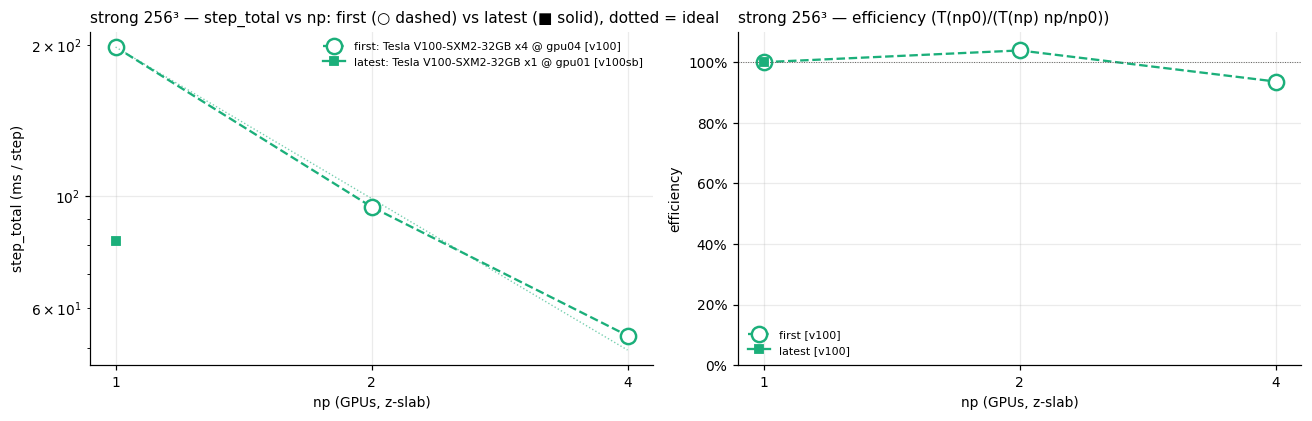

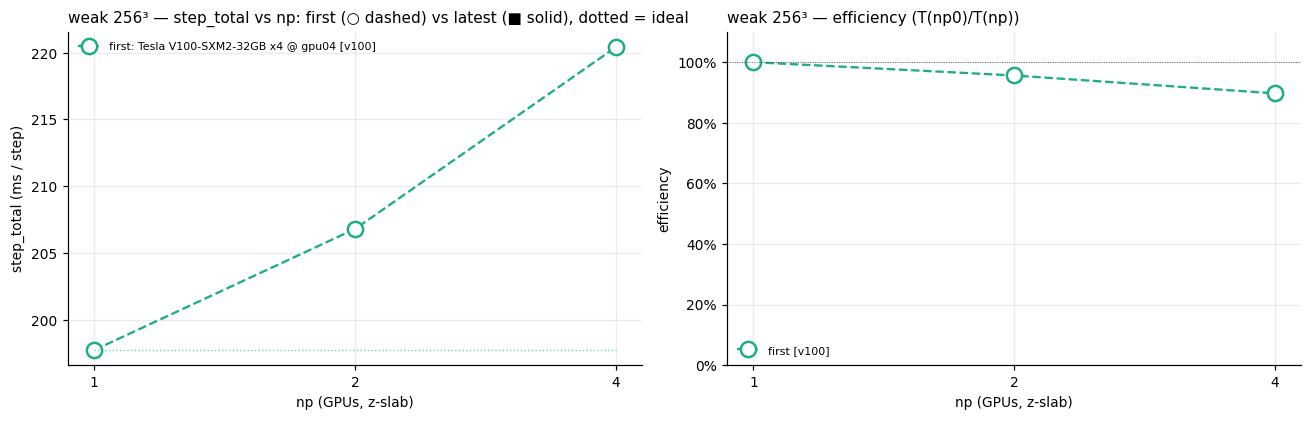

In [ ]:
def plot_total(mode, n):
    hws = sorted({k[0] for cases in (BEFORE, AFTER) for k in cases if k[1:3] == (mode, n)})
    if not hws:
        return
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.9))
    nps_all = sorted({k[3] for cases in (BEFORE, AFTER) for k in cases if k[1:3] == (mode, n)})
    for hw in hws:
        for cases, label, name in ((BEFORE, "before", "first"), (AFTER, "after", "latest")):
            ks = sorted(k for k in cases if k[:3] == (hw, mode, n))
            if not ks:
                continue
            nps = np.array([k[3] for k in ks]); t = np.array([cases[k]["step_total"] for k in ks])
            st = STYLE[label]; c = HW_COLOR[hw]
            ax1.plot(nps, t, color=c, marker=st["marker"], ls=st["ls"], mfc=st["mfc"] or c, ms=st["ms"], mew=st["mew"], zorder=st["z"],
                     label=f"{name}: {hw_desc(label, hw)}")
            ideal = t[0] * nps[0] / nps if mode == "strong" else np.full_like(t, t[0])
            if label == "before":
                ax1.plot(nps, ideal, color=c, ls=":", lw=0.9, alpha=0.6)
            eff = t[0] / (t * nps / nps[0]) if mode == "strong" else t[0] / t
            ax2.plot(nps, 100 * eff, color=c, marker=st["marker"], ls=st["ls"], mfc=st["mfc"] or c, ms=st["ms"], mew=st["mew"], zorder=st["z"], label=f"{name} [{hw}]")
    for ax in (ax1, ax2):
        ax.set_xscale("log", base=2); ax.xaxis.set_major_locator(FixedLocator(nps_all)); ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xticklabels([str(v) for v in nps_all]); ax.set_xlabel("np (GPUs, z-slab)")
    ax1.set_yscale("log" if mode == "strong" else "linear"); ax1.set_ylabel("step_total (ms / step)")
    ax1.set_title(f"{mode} {n}³ — step_total vs np: first (○ dashed) vs latest (■ solid), dotted = ideal", fontsize=10, loc="left")
    ax2.set_ylabel("efficiency"); ax2.yaxis.set_major_formatter(PercentFormatter()); ax2.set_ylim(0, 110); ax2.axhline(100, color="#52514e", lw=0.6, ls=":")
    ax2.set_title(f"{mode} {n}³ — efficiency ({'T(np0)/(T(np) np/np0)' if mode == 'strong' else 'T(np0)/T(np)'})", fontsize=10, loc="left")
    ax1.legend(frameon=False, fontsize=7.2, loc="best"); ax2.legend(frameon=False, fontsize=7.2, loc="lower left")
    fig.tight_layout()

for mode in ("strong", "weak"):
    for n in (256, 512):
        plot_total(mode, n)
plt.show()

## 2. 이벤트별 시간 — 처음(회색) vs 최신(파랑), 같은 기종·문제 크기·np

오른쪽은 감소량 = 처음 − 최신 (ms/step), 막대 위 숫자는 감소율 %. 두 바이너리가 모두 있는 조합만(np ≤ 4).

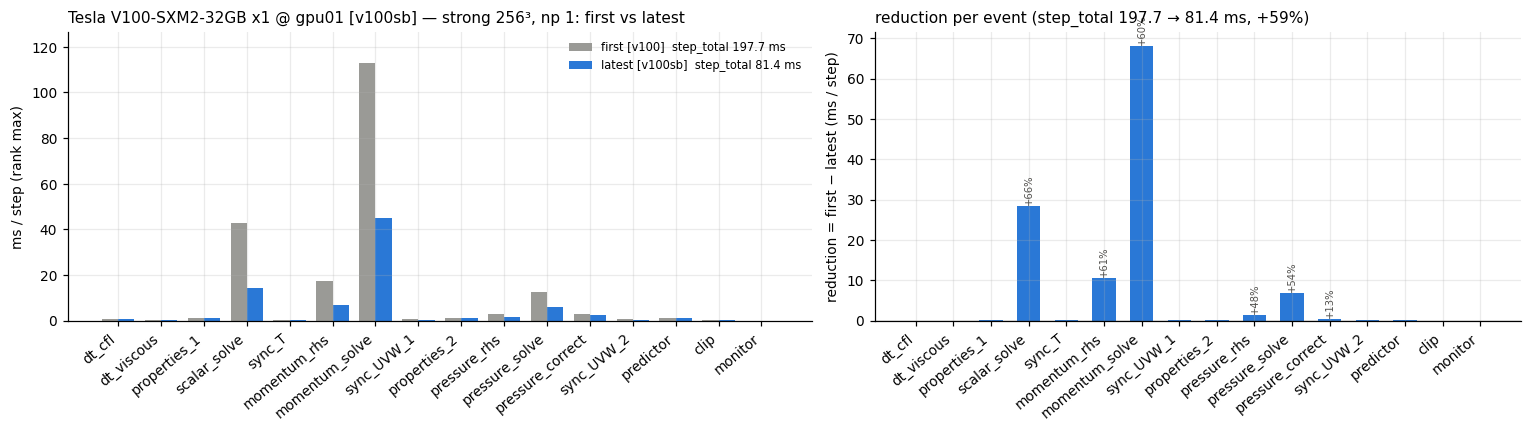

In [ ]:
def plot_first_latest(mode, hw, n, np_):
    k = (hw, mode, n, np_)
    if k not in BEFORE or k not in AFTER:
        return
    b, a = BEFORE[k], AFTER[k]
    vb = np.array([event_time(b, e) for e in EVENTS]); va = np.array([event_time(a, e) for e in EVENTS])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.0), gridspec_kw={"width_ratios": [1.15, 1]})
    xs = np.arange(len(EVENTS)); w = 0.38
    ax1.bar(xs - w / 2, vb, w, color="#9a9a96", label=f"first [{BEFORE_TAG[k]}]  step_total {b['step_total']:.1f} ms")
    ax1.bar(xs + w / 2, va, w, color="#2a78d6", label=f"latest [{AFTER_TAG[k]}]  step_total {a['step_total']:.1f} ms")
    ax1.set_xticks(xs); ax1.set_xticklabels(EVENTS, rotation=40, ha="right"); ax1.set_ylabel("ms / step (rank max)")
    ax1.set_title(f"{hw_desc('after', hw)} — {mode} {n}³, np {np_}: first vs latest", fontsize=10, loc="left")
    ax1.set_ylim(0, max(vb.max(), va.max()) * 1.12); ax1.legend(frameon=False, fontsize=7.5)
    d = vb - va; colors = ["#2a78d6" if v >= 0 else "#e34948" for v in d]
    ax2.bar(xs, d, 0.62, color=colors)
    for x, v, bv in zip(xs, d, vb):
        if bv > 0.02 * vb.max():
            ax2.annotate(f"{100 * v / bv:+.0f}%", (x, v), xytext=(0, 2 if v >= 0 else -9), textcoords="offset points", ha="center", fontsize=6.5, color="#52514e", rotation=90)
    ax2.axhline(0, color="#52514e", lw=0.8)
    ax2.set_xticks(xs); ax2.set_xticklabels(EVENTS, rotation=40, ha="right"); ax2.set_ylabel("reduction = first − latest (ms / step)")
    ax2.set_title(f"reduction per event (step_total {b['step_total']:.1f} → {a['step_total']:.1f} ms, {100*(1-a['step_total']/b['step_total']):+.0f}%)", fontsize=10, loc="left")
    fig.tight_layout()

for hw in ("h200", "v100", "a100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (1, 2, 4, 8):
                plot_first_latest(mode, hw, n, np_)
plt.show()

## 3. 요약표 — 처음 → 최신

In [ ]:
print(f"{'hw':5s} {'mode':6s} {'n':4s} {'np':3s} | {'first':>8s} {'latest':>8s} {'gain':>6s} {'speedup':>8s} | 가장 많이 줄어든 이벤트 (ms)")
for hw in ("h200", "v100", "a100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (1, 2, 4, 8):
                k = (hw, mode, n, np_)
                if k not in BEFORE or k not in AFTER:
                    continue
                b, a = BEFORE[k], AFTER[k]
                d = sorted(((event_time(b, e) - event_time(a, e), e) for e in EVENTS if e != TOTAL), reverse=True)[:3]
                print(f"{hw:5s} {mode:6s} {n:<4d} {np_:<3d} | {b['step_total']:8.1f} {a['step_total']:8.1f} {100*(1-a['step_total']/b['step_total']):5.0f}% {b['step_total']/a['step_total']:7.2f}x | " + ", ".join(f"{e} −{v:.1f}" for v, e in d))
print()
print("최신만 있는 조합(np 8 등):")
for k in sorted(AFTER):
    if k not in BEFORE:
        print(f"  {k[0]:5s} {k[1]:6s} {k[2]}^3 np{k[3]:<2d}  step_total {AFTER[k]['step_total']:7.1f} ms  [{AFTER_TAG[k]}]")

hw    mode   n    np  |    first   latest   gain  speedup | 가장 많이 줄어든 이벤트 (ms)
v100  strong 256  1   |    197.7     81.4    59%    2.43x | momentum_solve −68.2, scalar_solve −28.4, momentum_rhs −10.5

최신만 있는 조합(np 8 등):
